<a href="https://colab.research.google.com/github/abhisheksahoo6448/RBI-Calibrated-Tightening-Vs-Aggressive-Hike/blob/main/Inflation_%26_Repo_Rate_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [55]:
# Importing the Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [56]:
# Loading the dataset
df = pd.read_csv('processed_macro_data.csv', parse_dates = ['date'], index_col = ['date'])

In [57]:
# Checking for any Null Values
df.isnull().sum()

,0
inflation,0
repo_rate,0
iip_gap,0
fx_change,0


In [58]:
# Checking the data types of the variables
df.dtypes

,0
inflation,float64
repo_rate,float64
iip_gap,float64
fx_change,float64


In [59]:
# Checking if there is any duplicate present
df.duplicated().sum()

np.int64(0)

In [60]:
df

,inflation,repo_rate,iip_gap,fx_change
date,,,,
2023-01-01,6.50,6.25,24.381618,0.000000
2023-02-01,6.40,6.50,19.024351,0.219405
2023-03-01,5.70,6.50,28.201915,0.036487
2023-04-01,4.70,6.50,-13.436921,0.170213
2023-05-01,4.30,6.50,-8.335387,0.351984
2023-06-01,4.90,6.50,-8.126590,0.000000
2023-07-01,7.40,6.50,-9.858109,0.000000
2023-08-01,6.80,6.50,-5.876585,0.133043
2023-09-01,5.00,6.50,-7.614183,0.157024


In [61]:
# Importing time series libraries
from statsmodels.tsa.api import VAR

In [62]:
# Fitting the model
model = VAR(df)
results = model.fit(1)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [63]:
params = results.params.values
const = params[0]
A1 = params[1:]

In [64]:
const

array([ 1.91261233,  0.37818469, 18.51945359,  3.74333744])

In [65]:
params

array([[ 1.91261233e+00,  3.78184693e-01,  1.85194536e+01,
         3.74333744e+00],
       [ 9.40239371e-01,  3.93310970e-02,  3.57367896e-01,
        -8.57572204e-02],
       [-2.76464490e-01,  9.08399194e-01, -3.29504720e+00,
        -4.77075589e-01],
       [-1.93042969e-02,  2.30886874e-04,  3.92546559e-01,
        -7.42350224e-03],
       [ 8.62231381e-03, -1.91420147e-02, -1.78080583e+00,
        -4.45523848e-01]])

In [66]:
A1

array([[ 9.40239371e-01,  3.93310970e-02,  3.57367896e-01,
        -8.57572204e-02],
       [-2.76464490e-01,  9.08399194e-01, -3.29504720e+00,
        -4.77075589e-01],
       [-1.93042969e-02,  2.30886874e-04,  3.92546559e-01,
        -7.42350224e-03],
       [ 8.62231381e-03, -1.91420147e-02, -1.78080583e+00,
        -4.45523848e-01]])

In [67]:
df.iloc[-1].values

array([ 6.09      ,  5.5       ,  0.54721921, -0.77099396])

In [68]:
# Running simulation over 24 months
steps = 24
history_constant = [df.iloc[-1].values.copy()]
for t in range(steps):
    prev = history_constant[-1]
    y_next = const + np.dot(prev, A1)
    y_next[1] = 5.50 # Keep Repo Rate constant at 5.50%
    history_constant.append(y_next)

df_sim_const = pd.DataFrame(history_constant, columns=df.columns)
df_sim_const['Month'] = range(0, steps + 1)

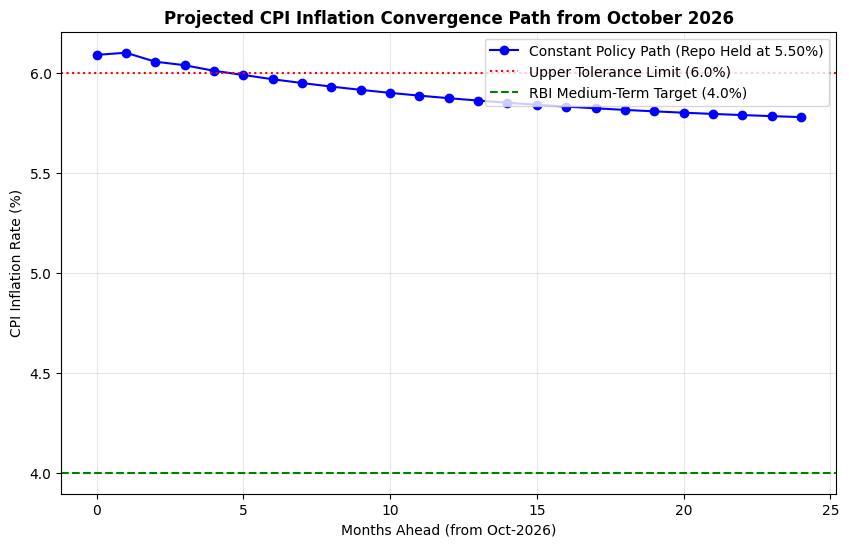

In [69]:
# Plotting Visualisation
plt.figure(figsize=(10, 6))
plt.plot(df_sim_const['Month'], df_sim_const['inflation'],
         label='Constant Policy Path (Repo Held at 5.50%)', color='blue', marker='o')

plt.axhline(6.0, color='red', linestyle=':', label='Upper Tolerance Limit (6.0%)')
plt.axhline(4.0, color='green', linestyle='--', label='RBI Medium-Term Target (4.0%)')
plt.title('Projected CPI Inflation Convergence Path from October 2026', fontsize=12, fontweight='bold')
plt.xlabel('Months Ahead (from Oct-2026)', fontsize=10)
plt.ylabel('CPI Inflation Rate (%)', fontsize=10)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.show()

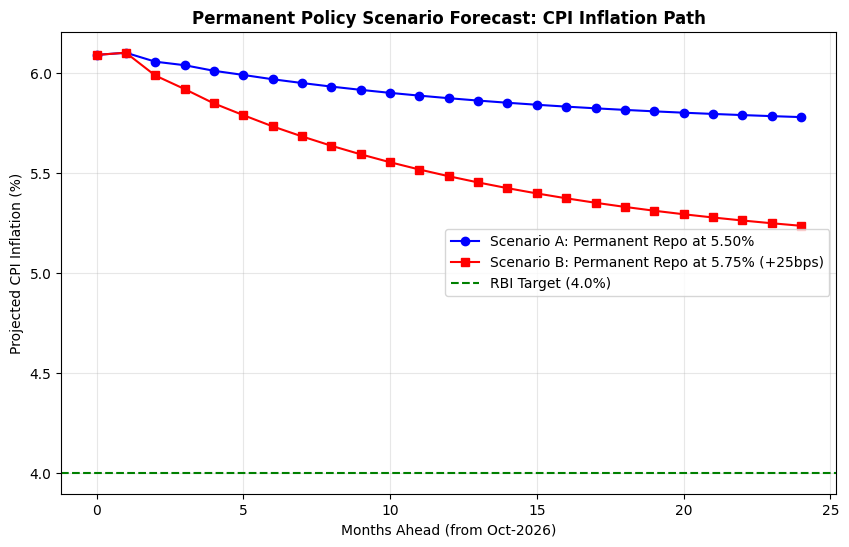

In [70]:
# Define Permanent Simulation Function
def run_permanent_sim(steps, repo_val):
    history = [df.iloc[-1].values.copy()]
    for t in range(steps):
        prev = history[-1]
        y_next = const + np.dot(prev, A1)
        y_next[1] = repo_val
        history.append(y_next)
    return pd.DataFrame(history, columns=df.columns)

# Simulate both paths over 24 months
steps = 24
df_sim_550 = run_permanent_sim(steps, 5.50)
df_sim_575 = run_permanent_sim(steps, 5.75)

# Plot the permanent trajectories
plt.figure(figsize=(10, 6))
plt.plot(range(25), df_sim_550['inflation'], label='Scenario A: Permanent Repo at 5.50%', color='blue', marker='o')
plt.plot(range(25), df_sim_575['inflation'], label='Scenario B: Permanent Repo at 5.75% (+25bps)', color='red', marker='s')
plt.axhline(4.0, color='green', linestyle='--', label='RBI Target (4.0%)')
plt.title('Permanent Policy Scenario Forecast: CPI Inflation Path', fontsize=12, fontweight='bold')
plt.xlabel('Months Ahead (from Oct-2026)', fontsize=10)
plt.ylabel('Projected CPI Inflation (%)', fontsize=10)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# **When the Monetary Policy Committee decides to raise / Increase the Policy Repo Rate by 25 basis points in the month of December**

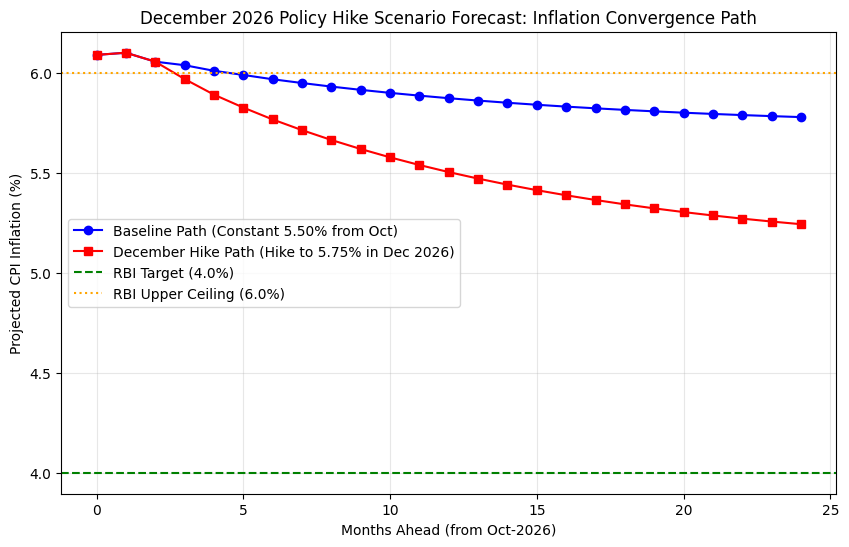

In [71]:
# Define Custom Simulation Function
def run_custom_sim(steps, repo_path):
    history = [df.iloc[-1].values.copy()] # Start at Oct-2026
    for t in range(steps):
        prev = history[-1]
        y_next = const + np.dot(prev, A1)
        y_next[1] = repo_path[t] # Set custom monthly policy path
        history.append(y_next)
    return pd.DataFrame(history, columns=df.columns)

# Define Scenario Paths
steps = 24
# December Hike Path: Month 1 (Nov-26) = 5.50%, Month 2 onwards (Dec-26+) = 5.75%
custom_repo_path = [5.50] + [5.75] * (steps - 1)
df_sim_custom = run_custom_sim(steps, custom_repo_path)
df_sim_custom['Month'] = range(0, steps + 1)

# Baseline path: constant at 5.50% permanently from October
baseline_repo_path = [5.50] * steps
df_sim_base = run_custom_sim(steps, baseline_repo_path)
df_sim_base['Month'] = range(0, steps + 1)

# Plot the pathways
plt.figure(figsize=(10, 6))
plt.plot(df_sim_base['Month'], df_sim_base['inflation'], label='Baseline Path (Constant 5.50% from Oct)', color='blue', marker='o')
plt.plot(df_sim_custom['Month'], df_sim_custom['inflation'], label='December Hike Path (Hike to 5.75% in Dec 2026)', color='red', marker='s')
plt.axhline(4.0, color='green', linestyle='--', label='RBI Target (4.0%)')
plt.axhline(6.0, color='orange', linestyle=':', label='RBI Upper Ceiling (6.0%)')
plt.title('December 2026 Policy Hike Scenario Forecast: Inflation Convergence Path')
plt.xlabel('Months Ahead (from Oct-2026)')
plt.ylabel('Projected CPI Inflation (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# **When MPC Decides to increase repo rate in December by **
1. **Moderate Hike : 25 bps hike**
2. **Aggressive Hike : 50 bps hike**


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


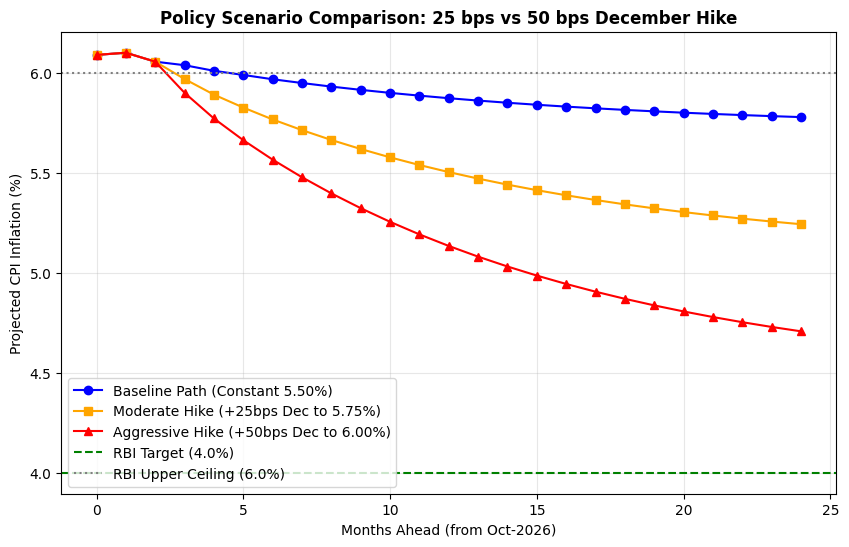

In [72]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.tsa.api import VAR
import matplotlib.pyplot as plt

# 1. Load processed macroeconomic dataset
df_processed = pd.read_csv('processed_macro_data.csv', parse_dates=['date'], index_col='date')

# 2. Fit VAR(1) Model
model = VAR(df_processed)
results = model.fit(1)
params = results.params.values
const = params[0]
A1 = params[1:]

# 3. Define Custom Simulation Function
def run_custom_sim(steps, repo_path):
    history = [df_processed.iloc[-1].values.copy()]
    for t in range(steps):
        prev = history[-1]
        y_next = const + np.dot(prev, A1)
        y_next[1] = repo_path[t] # Set custom monthly policy path
        history.append(y_next)
    return pd.DataFrame(history, columns=df_processed.columns)

# 4. Define Scenario Paths over 24 Months
steps = 24

# Path 1: Baseline (5.50% permanently)
path_base = [5.50] * steps
df_sim_base = run_custom_sim(steps, path_base)

# Path 2: 25 bps December Hike (Nov = 5.50%, Dec and onwards = 5.75%)
path_25bps = [5.50] + [5.75] * (steps - 1)
df_sim_25 = run_custom_sim(steps, path_25bps)

# 50 bps December Hike (Nov = 5.50%, Dec and onwards = 6.00%)
path_50bps = [5.50] + [6.00] * (steps - 1)
df_sim_50 = run_custom_sim(steps, path_50bps)

# Plot the three curves side-by-side
plt.figure(figsize=(10, 6))
plt.plot(range(25), df_sim_base['inflation'], label='Baseline Path (Constant 5.50%)', color='blue', marker='o')
plt.plot(range(25), df_sim_25['inflation'], label='Moderate Hike (+25bps Dec to 5.75%)', color='orange', marker='s')
plt.plot(range(25), df_sim_50['inflation'], label='Aggressive Hike (+50bps Dec to 6.00%)', color='red', marker='^')
plt.axhline(4.0, color='green', linestyle='--', label='RBI Target (4.0%)')
plt.axhline(6.0, color='gray', linestyle=':', label='RBI Upper Ceiling (6.0%)')
plt.title('Policy Scenario Comparison: 25 bps vs 50 bps December Hike', fontsize=12, fontweight='bold')
plt.xlabel('Months Ahead (from Oct-2026)', fontsize=10)
plt.ylabel('Projected CPI Inflation (%)', fontsize=10)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


**Staggered Hike :** 25 bps hike in December & 25 basis points in February

**Front Loaded Hike:** 50 bps hike in December & 25 bps hike in February

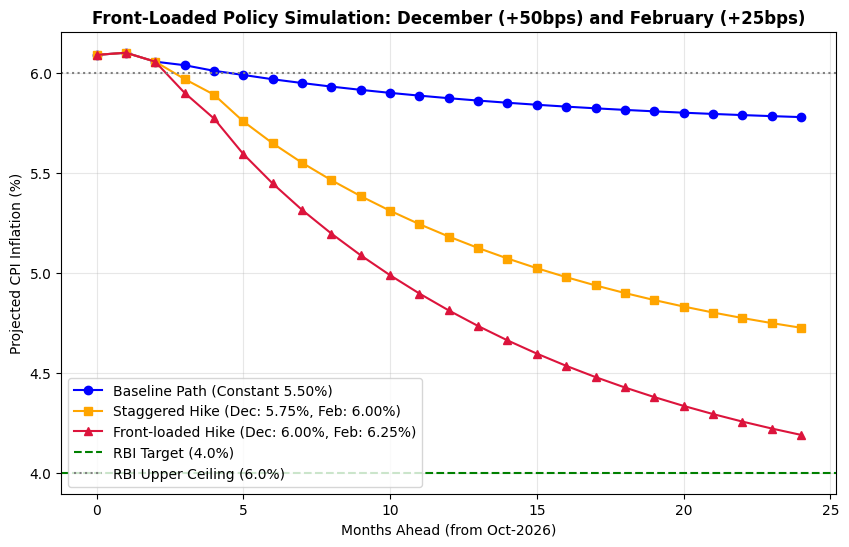

In [73]:
# Path 2: Staggered Hike (+25 bps Dec, +25 bps Feb)
path_staggered = [5.50, 5.75, 5.75, 6.00] + [6.00] * (steps - 4)
df_sim_staggered = run_custom_sim(steps, path_staggered)

# Path 3: Front-loaded Hike (+50 bps Dec, +25 bps Feb)
path_front = [5.50, 6.00, 6.00, 6.25] + [6.25] * (steps - 4)
df_sim_front = run_custom_sim(steps, path_front)

# Plot the comparative trajectories
plt.figure(figsize=(10, 6))
plt.plot(range(25), df_sim_base['inflation'], label='Baseline Path (Constant 5.50%)', color='blue', marker='o')
plt.plot(range(25), df_sim_staggered['inflation'], label='Staggered Hike (Dec: 5.75%, Feb: 6.00%)', color='orange', marker='s')
plt.plot(range(25), df_sim_front['inflation'], label='Front-loaded Hike (Dec: 6.00%, Feb: 6.25%)', color='crimson', marker='^')
plt.axhline(4.0, color='green', linestyle='--', label='RBI Target (4.0%)')
plt.axhline(6.0, color='gray', linestyle=':', label='RBI Upper Ceiling (6.0%)')
plt.title('Front-Loaded Policy Simulation: December (+50bps) and February (+25bps)', fontsize=12, fontweight='bold')
plt.xlabel('Months Ahead (from Oct-2026)', fontsize=10)
plt.ylabel('Projected CPI Inflation (%)', fontsize=10)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# **Status Of Exogenous Variables which are Index of Industrial Production & Foreign Exchange Rate (INR/USD)**

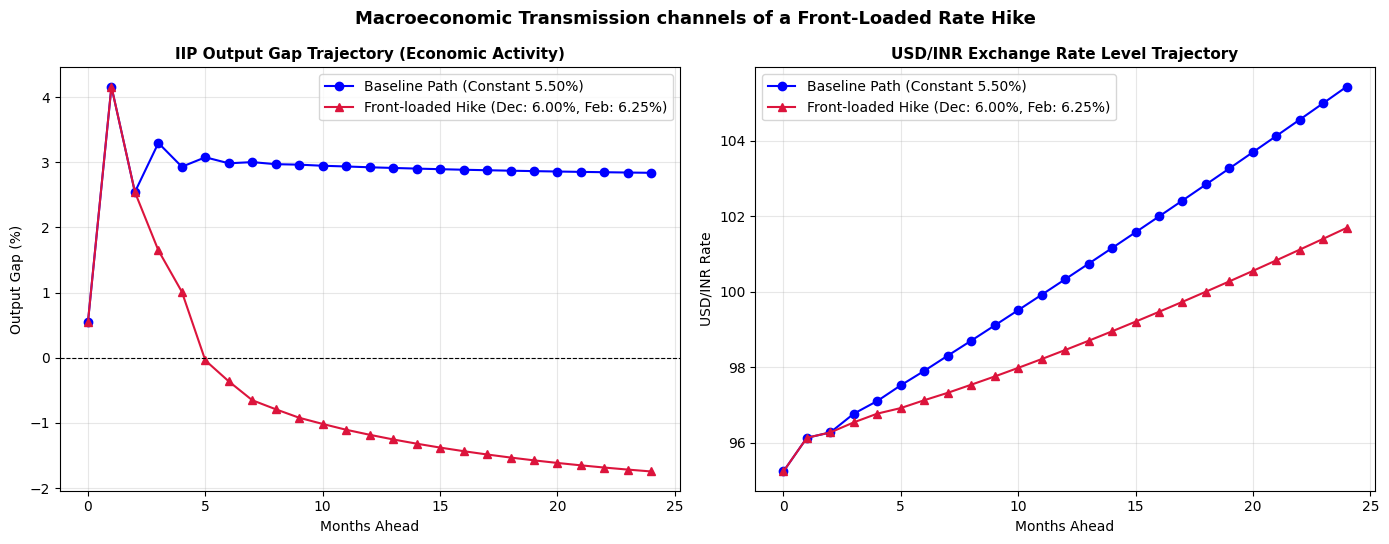

In [74]:
def reconstruct_fx(df_sim, initial_rate=95.24):
    rates = [initial_rate]
    for change in df_sim['fx_change'].iloc[1:]:
        rates.append(rates[-1] * (1 + change / 100))
    df_sim['fx_rate'] = rates
    return df_sim

df_sim_base = reconstruct_fx(df_sim_base)
df_sim_front = reconstruct_fx(df_sim_front)

# Plot Dual Channels
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Plot Output Gap
ax1.plot(range(25), df_sim_base['iip_gap'], label='Baseline Path (Constant 5.50%)', color='blue', marker='o')
ax1.plot(range(25), df_sim_front['iip_gap'], label='Front-loaded Hike (Dec: 6.00%, Feb: 6.25%)', color='crimson', marker='^')
ax1.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax1.set_title('IIP Output Gap Trajectory (Economic Activity)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Months Ahead')
ax1.set_ylabel('Output Gap (%)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot USD/INR FX Rate
ax2.plot(range(25), df_sim_base['fx_rate'], label='Baseline Path (Constant 5.50%)', color='blue', marker='o')
ax2.plot(range(25), df_sim_front['fx_rate'], label='Front-loaded Hike (Dec: 6.00%, Feb: 6.25%)', color='crimson', marker='^')
ax2.set_title('USD/INR Exchange Rate Level Trajectory', fontsize=11, fontweight='bold')
ax2.set_xlabel('Months Ahead')
ax2.set_ylabel('USD/INR Rate')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle('Macroeconomic Transmission channels of a Front-Loaded Rate Hike', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()